# 01 · Inventario y calidad de los datos de urgencias

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / 'src' / 'config.py').exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src import config
from src.db import consultar
from src.graficos import (
    CUADRICULA,
    GRISES_TECNICOS,
    MARCADORES,
    TEXTO_SECUNDARIO,
    aplicar_estilo,
    etiquetar_final,
    guardar_figura,
)
from src.privacidad import enmascarar_pequenos, suprimir_pequenos, tabla_segura

aplicar_estilo()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

## 1. Cobertura

Periodo cubierto, volumen mensual por tipo de visita y proporción de visitas que empiezan exactamente a medianoche. Según lo revisado en DBeaver, el periodo va de 2023-01-01 a mediados de julio de 2026, con julio de 2026 incompleto y agosto prácticamente vacío.

In [2]:
periodo = consultar('01_volumen_periodo')
suprimir_pequenos(periodo, ['n_visitas', 'n_visitas_urgencias', 'n_pacientes'])

,primera_fecha,ultima_fecha,n_visitas,n_visitas_urgencias,n_pacientes
0,2023-01-01,2026-08-13,1706001,598088,304457


In [3]:
mensual = consultar('01_volumen_mensual')
mensual['mes'] = pd.to_datetime(mensual['mes'])
volumen_mensual = mensual.pivot_table(
    index='mes', columns='tipo_visita', values='n_visitas', aggfunc='sum', fill_value=0
)
suprimir_pequenos(volumen_mensual, list(volumen_mensual.columns))

tipo_visita,Ambulatory Rehabilitation Visit,Emergency Room Visit,Inpatient Visit,No matching concept,Treatment urgency {Diagnosis}
mes,,,,,
2023-01-01,21022,16734,<10,<10,392
2023-02-01,19579,14802,<10,<10,294
2023-03-01,25762,17256,<10,<10,270
2023-04-01,21081,16066,<10,<10,342
2023-05-01,26210,18302,10,<10,306
2023-06-01,23624,16599,<10,<10,228
2023-07-01,25010,16300,<10,<10,272
2023-08-01,28344,16231,20,<10,206
2023-09-01,28248,15068,22,<10,152


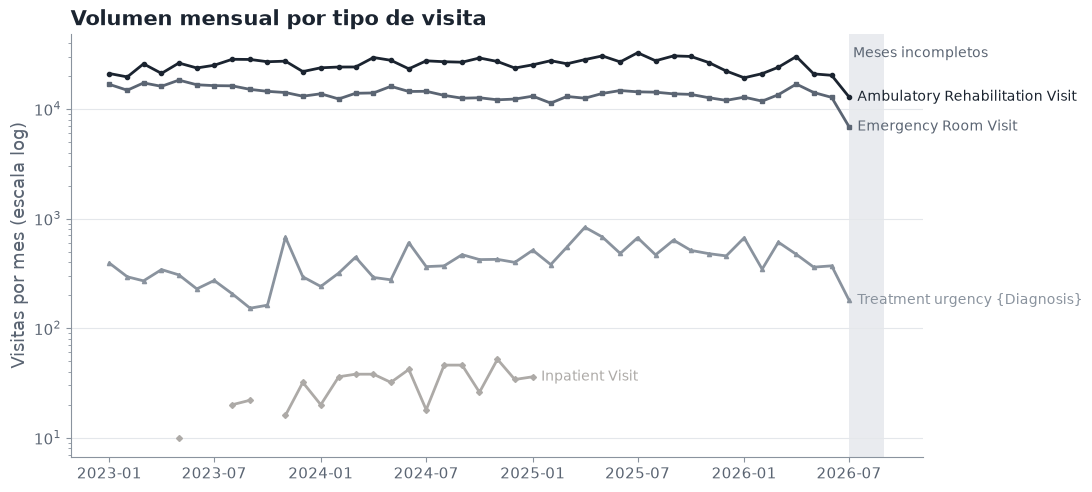

In [4]:
# Los cuatro tipos de visita con más volumen; los meses posteriores al corte se sombrean como incompletos.
principales = volumen_mensual.sum().sort_values(ascending=False).index[:4]
serie = enmascarar_pequenos(volumen_mensual[principales], volumen_mensual[principales])

fig, ax = plt.subplots(figsize=(11, 5.5))
for i, tipo in enumerate(principales):
    ax.plot(serie.index, serie[tipo], marker=MARCADORES[i], markersize=3, color=GRISES_TECNICOS[i])
    etiquetar_final(ax, serie.index, serie[tipo], tipo, color=GRISES_TECNICOS[i])
fin_eje = serie.index.max() + pd.offsets.MonthEnd(1)
ax.axvspan(config.FECHA_CORTE_TENDENCIAS, fin_eje, color=CUADRICULA, alpha=0.8, linewidth=0)
ax.text(
    config.FECHA_CORTE_TENDENCIAS, 0.97, ' Meses incompletos',
    transform=ax.get_xaxis_transform(), va='top', color=TEXTO_SECUNDARIO, fontsize=10,
)
ax.set_yscale('log')
ax.set_ylabel('Visitas por mes (escala log)')
ax.set_title('Volumen mensual por tipo de visita')
guardar_figura(fig, '01_volumen_mensual_tipo')
plt.show()

In [5]:
medianoche = consultar('01_hora_medianoche').set_index(['concepto_visita', 'tipo_visita'])
tabla_segura(medianoche)

,,n_visitas,n_medianoche,pct_medianoche
concepto_visita,tipo_visita,,,
581479,Ambulatory Rehabilitation Visit,1089461,1134,0.1
9203,Emergency Room Visit,598088,<10,suprimido
3045729,Treatment urgency {Diagnosis},17858,<10,suprimido
9201,Inpatient Visit,592,<10,suprimido
0,No matching concept,<10,<10,suprimido


## 2. Conceptos

Tipos de visita y de etapa traducidos con `concept`, y qué etapas aparecen dentro de cada tipo de visita. 

In [6]:
tipos_visita = consultar('01_tipos_visita').set_index(['concepto_visita', 'tipo_visita', 'vocabulario'])
tabla_segura(tipos_visita)

,,,n_visitas,n_pacientes
concepto_visita,tipo_visita,vocabulario,,
581479,Ambulatory Rehabilitation Visit,Visit,1089461,158563
9203,Emergency Room Visit,Visit,598088,231083
3045729,Treatment urgency {Diagnosis},LOINC,17858,15319
9201,Inpatient Visit,Visit,592,521
0,No matching concept,None,<10,<10


In [7]:
tipos_etapa = consultar('01_tipos_etapa').set_index(['concepto_etapa', 'etapa', 'vocabulario'])
tabla_segura(tipos_etapa)

,,,n_detalles,n_visitas
concepto_etapa,etapa,vocabulario,,
581479,Ambulatory Rehabilitation Visit,Visit,1539340,1230996
3045729,Treatment urgency {Diagnosis},LOINC,1152191,642577
9203,Emergency Room Visit,Visit,481481,448544
9201,Inpatient Visit,Visit,108601,69344


In [8]:
etapas_por_tipo = consultar('01_etapas_por_tipo_visita').set_index(
    ['concepto_visita', 'tipo_visita', 'concepto_etapa', 'etapa']
)
tabla_segura(etapas_por_tipo)

n_detalles n_visitas
concepto_visita tipo_visita                     concepto_etapa etapa                                               
0               No matching concept             581479         Ambulatory Rehabilitation Visit        <10       <10
9201            Inpatient Visit                 9201           Inpatient Visit                        737       589
                                                581479         Ambulatory Rehabilitation Visit        195       195
                                                3045729        Treatment urgency {Diagnosis}          110        73
                                                9203           Emergency Room Visit                    31        31
9203            Emergency Room Visit            3045729        Treatment urgency {Diagnosis}       855250    470002
                                                9203           Emergency Room Visit                419140    386203
                                                581479         Ambulatory Rehabilitation Visit     167902    167516
                                                9201           Inpatient Visit                      74006     47754
581479          Ambulatory Rehabilitation Visit 581479         Ambulatory Rehabilitation Visit    1366121   1058171
                                                3045729        Treatment urgency {Diagnosis}       259806    154690
                                                9203           Emergency Room Visit                 61387     61387
                                                9201           Inpatient Visit                      25859     15839
3045729         Treatment urgency {Diagnosis}   3045729        Treatment urgency {Diagnosis}        37000     17790
                                                9201           Inpatient Visit                       7908      5108
                                                581479         Ambulatory Rehabilitation Visit       5120      5112
                                                9203           Emergency Room Visit                   923       923

## 3. Duraciones

Duración registrada de la visita completa (se espera que sea 0 en todas, porque `visit_end_datetime` es igual a `visit_start_datetime`) y de cada etapa (`visit_detail`). Por eso el LOS se reconstruye desde las etapas.

In [9]:
duracion_visitas = consultar('01_duracion_visitas').set_index(['concepto_visita', 'tipo_visita'])
tabla_segura(duracion_visitas)

,,n,n_sin_fin,pct_sin_fin,n_negativas,pct_negativas,n_cero,pct_cero,p10_h,p50_h,p90_h,p99_h
concepto_visita,tipo_visita,,,,,,,,,,,
581479,Ambulatory Rehabilitation Visit,1089461,<10,suprimido,<10,suprimido,1089461,100.0,0.0,0.0,0.0,0.0
9203,Emergency Room Visit,598088,<10,suprimido,<10,suprimido,598088,100.0,0.0,0.0,0.0,0.0
3045729,Treatment urgency {Diagnosis},17858,<10,suprimido,<10,suprimido,17858,100.0,0.0,0.0,0.0,0.0
9201,Inpatient Visit,592,<10,suprimido,<10,suprimido,592,100.0,0.0,0.0,0.0,0.0
0,No matching concept,<10,<10,suprimido,<10,suprimido,<10,suprimido,suprimido,suprimido,suprimido,suprimido


In [10]:
duracion_etapas = consultar('01_duracion_etapas').set_index(['concepto_etapa', 'etapa'])
tabla_segura(duracion_etapas)

,,n,n_sin_fin,pct_sin_fin,n_negativas,pct_negativas,n_cero,pct_cero,p10_h,p50_h,p90_h,p99_h
concepto_etapa,etapa,,,,,,,,,,,
581479,Ambulatory Rehabilitation Visit,1539340,<10,suprimido,<10,suprimido,1539340,100.00,0.00,0.00,0.00,0.00
3045729,Treatment urgency {Diagnosis},1152191,<10,suprimido,<10,suprimido,443359,38.48,0.00,1.17,12.58,76.36
9203,Emergency Room Visit,481481,<10,suprimido,<10,suprimido,111309,23.12,0.00,0.05,0.10,0.19
9201,Inpatient Visit,108601,<10,suprimido,<10,suprimido,3533,3.25,4.71,45.96,188.20,550.92


In [ ]:
# Distribución de la duración de las etapas con duración positiva (bins de 1/4 de década).
# Las etapas instantáneas (duración 0, como 581479) no aparecen en esta figura; ver n_cero en la tabla.
histograma = consultar('01_histograma_duracion_etapas')
histograma['bin_log10_h'] = histograma['bin_log10_h'].astype(float)
etapas_graf = [
    config.CONCEPTO_URGENCIAS, config.CONCEPTO_SEGMENTO, config.CONCEPTO_PISO, config.CONCEPTO_AMBULATORIO
]

fig, ax = plt.subplots(figsize=(11, 5.5))
for i, concepto in enumerate(etapas_graf):
    datos = histograma[histograma['concepto_etapa'] == concepto].sort_values('bin_log10_h')
    if datos.empty:
        continue
    proporcion = (datos['n_detalles'] / datos['n_detalles'].sum()).where(datos['n_detalles'] >= config.MIN_CELDA)
    centro_bin = 10 ** (datos['bin_log10_h'] + 0.125)
    etiqueta = f"{datos['etapa'].iloc[0]} ({concepto})"
    ax.plot(centro_bin, proporcion, marker=MARCADORES[i], markersize=4, color=GRISES_TECNICOS[i])
    etiquetar_final(ax, centro_bin, proporcion, etiqueta, color=GRISES_TECNICOS[i])
for horas, texto in [(1 / 60, '1 min'), (1, '1 h'), (24, '24 h')]:
    ax.axvline(horas, color=TEXTO_SECUNDARIO, linestyle='--', linewidth=1)
    ax.annotate(texto, xy=(horas, 1), xycoords=('data', 'axes fraction'), xytext=(3, -14),
                textcoords='offset points', color=TEXTO_SECUNDARIO, fontsize=10)
ax.set_xscale('log')
ax.set_xlabel('Duración de la etapa en horas (escala log)')
ax.set_ylabel('Proporción de etapas de ese tipo')
ax.set_title('Duración de las etapas (visit_detail)')
guardar_figura(fig, '01_duracion_etapas')
plt.show()

## 4. Desplazamiento de etapas

Minutos entre el inicio de cada etapa y la llegada en visitas de urgencias, e histograma de los días de desplazamiento de las etapas que empiezan más de 1 hora antes de la llegada (D2). En DBeaver se observó que estos desplazamientos se concentran entre 14 y 27 días (pico en 15–16), lo que sugiere un artefacto de anonimización por confirmar con el hospital.

In [11]:
inicio_vs_llegada = consultar('01_inicio_etapas_vs_llegada').set_index(['concepto_etapa', 'etapa'])
tabla_segura(inicio_vs_llegada)

,,n,n_igual_llegada,pct_igual_llegada,n_desplazadas,pct_desplazadas,p01_min,p05_min,p10_min,p50_min,p90_min,p99_min
concepto_etapa,etapa,,,,,,,,,,,
3045729,Treatment urgency {Diagnosis},855250,<10,suprimido,118405,13.84,-29373.21,-24839.32,-22787.76,4.53,353.80,3395.90
9203,Emergency Room Visit,419140,373567,89.13,32622,7.78,-27436.64,-23253.12,-0.07,0.00,0.00,0.00
581479,Ambulatory Rehabilitation Visit,167902,<10,suprimido,167855,99.97,-37412.88,-30690.72,-27853.43,-24093.49,-21726.86,-20621.07
9201,Inpatient Visit,74006,<10,suprimido,10492,14.18,-28381.24,-23269.84,-20448.88,1509.03,7956.32,31579.02


In [12]:
dias = consultar('01_desplazamiento_dias')
matriz_dias = dias.pivot_table(
    index='dias_desplazamiento', columns='etapa', values='n_detalles', aggfunc='sum', fill_value=0
)
matriz_dias = matriz_dias[matriz_dias.sum().sort_values(ascending=False).index]
suprimir_pequenos(matriz_dias, list(matriz_dias.columns))

etapa,Ambulatory Rehabilitation Visit,Treatment urgency {Diagnosis},Emergency Room Visit,Inpatient Visit
dias_desplazamiento,,,,
0,<10,<10,<10,26
1,<10,<10,<10,34
2,<10,<10,<10,39
3,<10,<10,<10,36
4,<10,10,<10,50
...,...,...,...,...
316,<10,<10,<10,<10
321,<10,<10,<10,<10
331,<10,<10,<10,<10


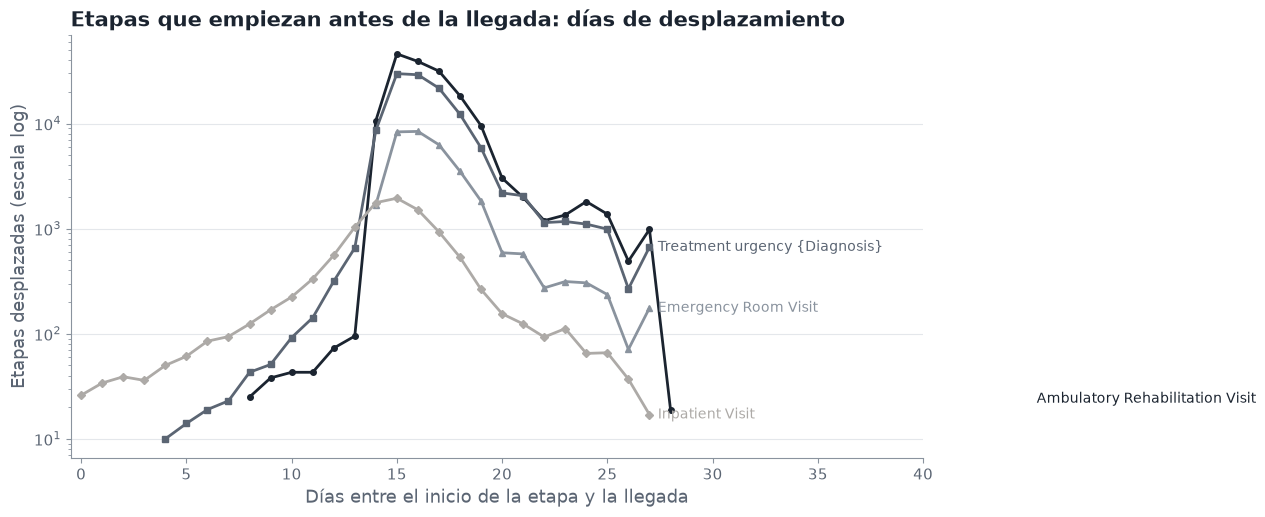

In [13]:
grafico_dias = enmascarar_pequenos(matriz_dias, matriz_dias)
fig, ax = plt.subplots(figsize=(11, 5.5))
for i, etapa in enumerate(grafico_dias.columns[:4]):
    ax.plot(grafico_dias.index, grafico_dias[etapa], marker=MARCADORES[i], markersize=4, color=GRISES_TECNICOS[i])
    etiquetar_final(ax, grafico_dias.index, grafico_dias[etapa], etapa, color=GRISES_TECNICOS[i])
ax.set_yscale('log')
ax.set_xlim(-0.5, min(40, grafico_dias.index.max() + 0.5))
ax.set_xlabel('Días entre el inicio de la etapa y la llegada')
ax.set_ylabel('Etapas desplazadas (escala log)')
ax.set_title('Etapas que empiezan antes de la llegada: días de desplazamiento')
guardar_figura(fig, '01_desplazamiento_dias')
plt.show()

## 5. Transiciones entre etapas

Etapas consecutivas dentro de una misma visita de urgencias (sin etapas desplazadas). El gap es el inicio de la etapa siguiente menos el fin de la actual: negativo indica traslape y cero indica etapas contiguas.

In [14]:
transiciones = consultar('01_transiciones').set_index(
    ['concepto_origen', 'etapa_origen', 'concepto_destino', 'etapa_destino']
)
tabla_segura(transiciones)

n n_gap_nulo pct_gap_nulo n_traslape pct_traslape  \
concepto_origen etapa_origen                    concepto_destino etapa_destino                                                                             
9203            Emergency Room Visit            3045729          Treatment urgency {Diagnosis}    295318        <10    suprimido     275780        93.38   
3045729         Treatment urgency {Diagnosis}   3045729          Treatment urgency {Diagnosis}    284257        <10    suprimido        511         0.18   
                                                9201             Inpatient Visit                   40874        <10    suprimido        212         0.52   
9201            Inpatient Visit                 9201             Inpatient Visit                   22149        <10    suprimido        198         0.89   
9203            Emergency Room Visit            9203             Emergency Room Visit                408        <10    suprimido        198        48.53   
                                                9201             Inpatient Visit                     132        <10    suprimido        <10    suprimido   
3045729         Treatment urgency {Diagnosis}   9203             Emergency Room Visit                 54        <10    suprimido         34        62.96   
                                                581479           Ambulatory Rehabilitation Visit      32        <10    suprimido        <10    suprimido   
9201            Inpatient Visit                 3045729          Treatment urgency {Diagnosis}        23        <10    suprimido        <10    suprimido   
                                                9203             Emergency Room Visit                 13        <10    suprimido         13        100.0   
                                                581479           Ambulatory Rehabilitation Visit     <10        <10    suprimido        <10    suprimido   
9203            Emergency Room Visit            581479           Ambulatory Rehabilitation Visit     <10        <10    suprimido        <10    suprimido   
581479          Ambulatory Rehabilitation Visit 3045729          Treatment urgency {Diagnosis}       <10        <10    suprimido        <10    suprimido   
                                                9201             Inpatient Visit                     <10        <10    suprimido        <10    suprimido   

                                                                                                 n_contiguas pct_contiguas p10_gap_min p50_gap_min p90_gap_min  
concepto_origen etapa_origen                    concepto_destino etapa_destino                                                                                  
9203            Emergency Room Visit            3045729          Treatment urgency {Diagnosis}         17363          5.88       -0.03       -0.02       -0.02  
3045729         Treatment urgency {Diagnosis}   3045729          Treatment urgency {Diagnosis}        272631         95.91         0.0         0.0         0.0  
                                                9201             Inpatient Visit                       32072         78.47         0.0         0.0     1308.23  
9201            Inpatient Visit                 9201             Inpatient Visit                       21806         98.45         0.0         0.0         0.0  
9203            Emergency Room Visit            9203             Emergency Room Visit                    210         51.47   -15841.44         0.0         0.0  
                                                9201             Inpatient Visit                         <10     suprimido      143.34      818.79    14023.06  
3045729         Treatment urgency {Diagnosis}   9203             Emergency Room Visit                     20         37.04   -16033.34     -870.57         0.0  
                                                581479           Ambulatory Rehabilitation Visit         <10     suprimido     1035.53     10562.9    31842.9

## 6. Fragmentación de visitas

Intervalo entre visitas de urgencias consecutivas del mismo paciente, medido desde el fin de la anterior hasta la llegada de la siguiente. Una visita previa es corta si dura menos de 5 minutos. El quiebre de la distribución en 1 hora sustenta el umbral de fusión de episodios (D4).

In [15]:
gaps = consultar('01_gap_visitas_consecutivas')
matriz_gaps = gaps.pivot_table(
    index='categoria', columns='duracion_previa', values='n_pares', aggfunc='sum', fill_value=0
).sort_index()
suprimir_pequenos(matriz_gaps, list(matriz_gaps.columns))

duracion_previa,corta,larga,sin_fin
categoria,,,
00 misma llegada,30282,32497,9174
01 traslapada,822,18820,<10
02 0-10 min,10476,3191,3305
03 10-20 min,4633,1407,1353
04 20-30 min,2758,952,701
05 30-45 min,2318,918,619
06 45-60 min,1398,549,361
07 60-90 min,1426,514,364
08 90-120 min,571,278,146


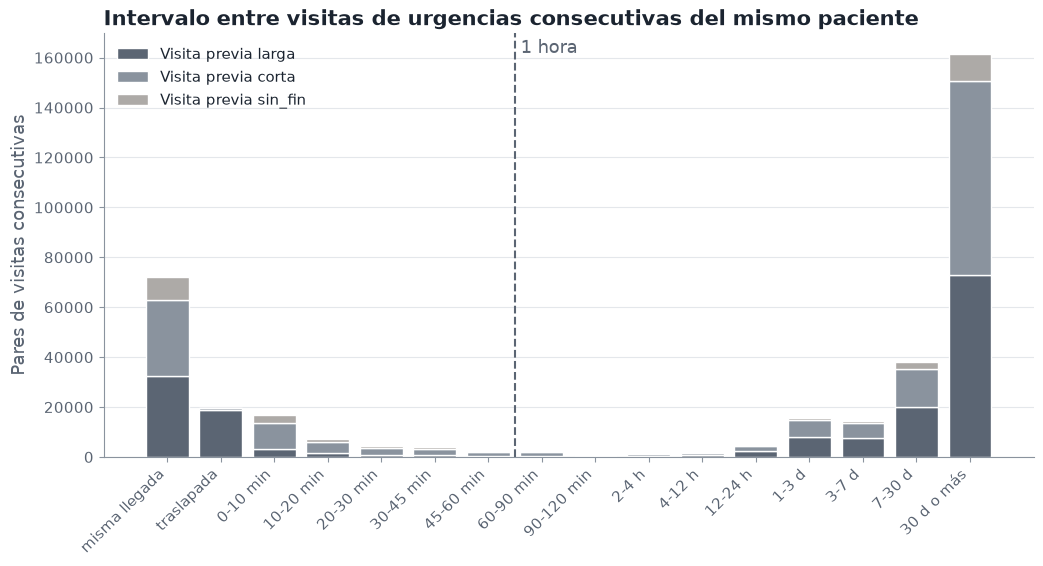

In [16]:
categorias = list(matriz_gaps.index)
etiquetas = [c.split(' ', 1)[1] for c in categorias]
grafico_gaps = enmascarar_pequenos(matriz_gaps, matriz_gaps).fillna(0)
colores = {'larga': GRISES_TECNICOS[1], 'corta': GRISES_TECNICOS[2], 'sin_fin': GRISES_TECNICOS[3]}

fig, ax = plt.subplots(figsize=(12, 5.5))
base = np.zeros(len(grafico_gaps))
for columna in [c for c in ['larga', 'corta', 'sin_fin'] if c in grafico_gaps.columns]:
    ax.bar(range(len(grafico_gaps)), grafico_gaps[columna], bottom=base, color=colores[columna],
           edgecolor='white', linewidth=1, label=f'Visita previa {columna}')
    base = base + grafico_gaps[columna].to_numpy()
primera_sobre_1h = next((i for i, c in enumerate(categorias) if c.startswith('07')), None)
if primera_sobre_1h is not None:
    ax.axvline(primera_sobre_1h - 0.5, color=TEXTO_SECUNDARIO, linestyle='--', linewidth=1.5)
    ax.annotate('1 hora', xy=(primera_sobre_1h - 0.5, 1), xycoords=('data', 'axes fraction'),
                xytext=(4, -14), textcoords='offset points', color=TEXTO_SECUNDARIO)
ax.set_xticks(range(len(grafico_gaps)), etiquetas, rotation=45, ha='right')
ax.set_ylabel('Pares de visitas consecutivas')
ax.set_title('Intervalo entre visitas de urgencias consecutivas del mismo paciente')
ax.legend()
guardar_figura(fig, '01_fragmentacion_visitas')
plt.show()

## 7. Mediciones

Las 50 mediciones más frecuentes y su vocabulario. 

In [17]:
mediciones = consultar('01_mediciones_top').set_index(['concepto_medicion', 'medicion', 'vocabulario', 'dominio'])
tabla_segura(mediciones)

,,,,n_registros,n_con_valor,n_visitas
concepto_medicion,medicion,vocabulario,dominio,,,
0,No matching concept,None,Metadata,8876114,5445445,153621
4016928,"Hemogram, automated, with RBC, WBC, Hgb, Hct, Indices, Platelet count, and automated complete WBC differential",SNOMED,Measurement,5706597,3128262,70917
4074649,Urea nitrogen measurement,SNOMED,Measurement,171380,203,47985
3024641,Urea nitrogen [Moles/volume] in Serum or Plasma,LOINC,Measurement,171317,204,47969
4245152,Potassium measurement,SNOMED,Measurement,132711,132204,26768
4154489,Serum potassium measurement,SNOMED,Measurement,132674,132167,26766
4097430,Sodium measurement,SNOMED,Measurement,127393,126947,26669
3019550,Sodium [Moles/volume] in Serum or Plasma,LOINC,Measurement,127363,126915,26665
3014576,Chloride [Moles/volume] in Serum or Plasma,LOINC,Measurement,95998,95998,24473


In [18]:
vocabularios = consultar('01_mediciones_vocabulario').set_index('vocabulario')
tabla_segura(vocabularios)

,n_registros,n_conceptos
vocabulario,,
None,8876114,<10
SNOMED,7053374,50
LOINC,643972,20
ICD10CM,2428,<10


## 8. Visitas sin detalle y edades imposibles

Visitas de urgencias sin ningún `visit_detail` (en DBeaver se contaron alrededor de 53 mil) o con solo etapas desplazadas; ambas quedan fuera de la extracción del notebook 02. Luego, la edad al llegar y los valores imposibles (D8).

In [19]:
sin_detalle = consultar('01_visitas_sin_detalle')
sin_detalle['mes'] = pd.to_datetime(sin_detalle['mes'])
sin_detalle = sin_detalle.set_index('mes')
tabla_segura(sin_detalle)

,n,n_sin_detalle,pct_sin_detalle,n_solo_desplazados,pct_solo_desplazados
mes,,,,,
2023-01-01,16734,1394,8.33,10,0.06
2023-02-01,14802,1219,8.24,34,0.23
2023-03-01,17256,1409,8.17,35,0.2
2023-04-01,16066,1240,7.72,25,0.16
2023-05-01,18302,1562,8.53,33,0.18
2023-06-01,16599,1500,9.04,17,0.1
2023-07-01,16300,1300,7.98,28,0.17
2023-08-01,16231,1253,7.72,16,0.1
2023-09-01,15068,1253,8.32,17,0.11


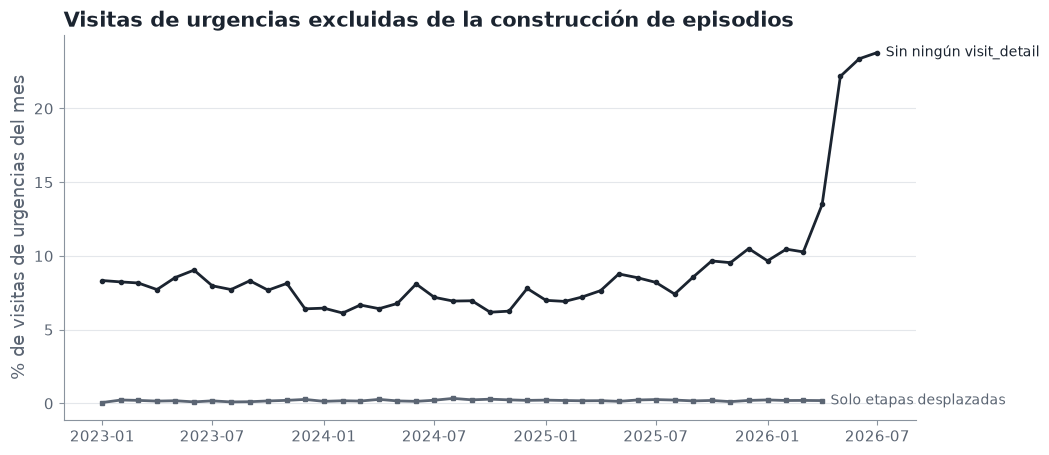

In [20]:
fig, ax = plt.subplots(figsize=(11, 5))
for i, (columna, conteo, texto) in enumerate([
    ('pct_sin_detalle', 'n_sin_detalle', 'Sin ningún visit_detail'),
    ('pct_solo_desplazados', 'n_solo_desplazados', 'Solo etapas desplazadas'),
]):
    valores = sin_detalle[columna].where(sin_detalle[conteo] >= config.MIN_CELDA)
    ax.plot(sin_detalle.index, valores, marker=MARCADORES[i], markersize=3, color=GRISES_TECNICOS[i])
    etiquetar_final(ax, sin_detalle.index, valores, texto, color=GRISES_TECNICOS[i])
ax.set_ylabel('% de visitas de urgencias del mes')
ax.set_title('Visitas de urgencias excluidas de la construcción de episodios')
guardar_figura(fig, '01_visitas_sin_detalle')
plt.show()

In [21]:
edades = consultar('01_edades')
resumen_edades = edades.groupby('categoria')['n_visitas'].sum().to_frame()
resumen_edades['pct_visitas'] = 100 * resumen_edades['n_visitas'] / resumen_edades['n_visitas'].sum()
tabla_segura(resumen_edades)

,n_visitas,pct_visitas
categoria,,
adulto,373395,62.43
adulto_mayor,69173,11.57
mayor_110,23,0.0
negativa,<10,suprimido
pediatria,155496,26.0


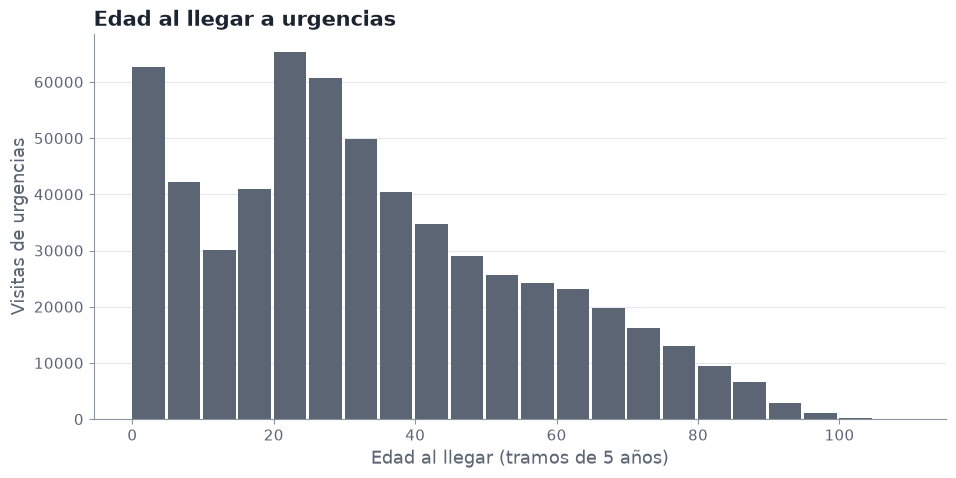

In [22]:
bandas = edades.dropna(subset=['banda_5']).groupby('banda_5')['n_visitas'].sum()
bandas.index = bandas.index.astype(int)
bandas_graf = bandas.where(bandas >= config.MIN_CELDA)

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(bandas_graf.index, bandas_graf.to_numpy(), width=4.6, align='edge', color=GRISES_TECNICOS[1], linewidth=0)
ax.set_xlabel('Edad al llegar (tramos de 5 años)')
ax.set_ylabel('Visitas de urgencias')
ax.set_title('Edad al llegar a urgencias')
guardar_figura(fig, '01_edades')
plt.show()